# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [16]:
print("Root:", ROOT)
print("Data folder:", DATA)
print("Data folder exists:", DATA.exists())
print("Data folder contents:", list(DATA.iterdir()) if DATA.exists() else "Missing")

Root: /Users/moana/fall_2026/coding/Coding-2-Python-for-Data-Analysis/coding2-debug-12-simple-linear-regression
Data folder: /Users/moana/fall_2026/coding/Coding-2-Python-for-Data-Analysis/coding2-debug-12-simple-linear-regression/data
Data folder exists: True
Data folder contents: [PosixPath('/Users/moana/fall_2026/coding/Coding-2-Python-for-Data-Analysis/coding2-debug-12-simple-linear-regression/data/career_outcomes.csv')]


In [17]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

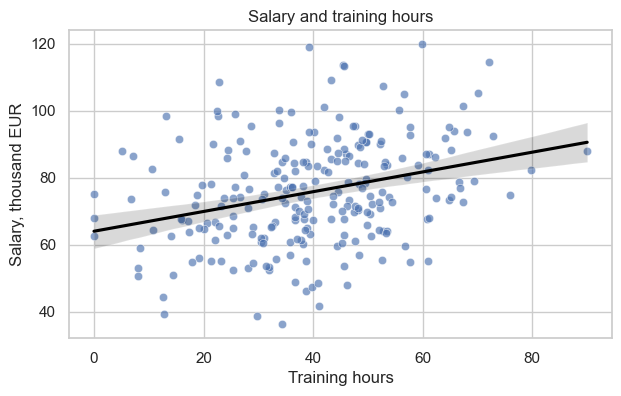

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [19]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        09:30:37   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [30]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
effect_per_hour = slope * training_sd
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per one-standard-deviation increase in training: {effect_per_hour:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per one-standard-deviation increase in training: 4.75 thousand EUR


In [21]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "mean_ci_lower", "mean_ci_upper"]])

,training_hours,mean,mean_ci_lower,mean_ci_upper
0,10,66.922063,62.920192,70.923934
1,40,75.775371,73.870950,77.679793
2,80,87.579782,82.431712,92.727853


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

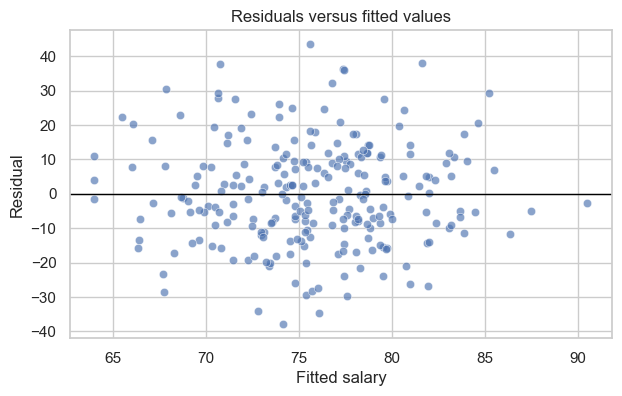

In [22]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

A one-hour increase in training is associated, on average, with a €295.10 increase in salary (0.2951 thousand EUR).

One possible omitted variable is prior work experience, because people with more work experience may both earn higher salaries and have completed more training. Therefore, omitting this variable could confound the estimated association.

In [23]:
print(df.columns)

Index(['experience_years', 'education_years', 'training_hours', 'sector',
       'remote', 'ai_tool_use', 'salary_k_eur', 'promoted'],
      dtype='str')


In [24]:
print(df.shape)

(240, 8)


In [25]:
print(model.fittedvalues.shape)

(240,)


In [26]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        09:30:38   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [27]:
# Use only the observations that were used in the model
diagnostics = df.loc[model.model.data.row_labels].copy()
diagnostics['fitted'] = model.fittedvalues
diagnostics['residual'] = model.resid

[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

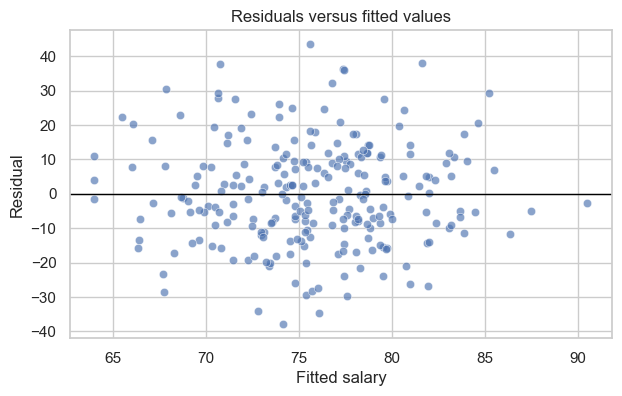

In [28]:
# Then proceed with your plotting code
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")